## Setup
If you have `adata_tcga_preprocessed.h5ad`, run this cell and the imports cell, then skip straight to **VAE Model** (the cells in between rebuild that file from the raw TSVs).

In [1]:
import os, glob

def find_data_dir(filename):
    """Folder holding `filename`: here, anywhere under /content (Upload to Colab), or in Drive."""
    if os.path.exists(filename):
        return os.getcwd()
    for pattern in [f"/content/{filename}", f"/content/*/{filename}", f"/content/drive/MyDrive/**/{filename}"]:
        hits = glob.glob(pattern, recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError(f"{filename} isn't on this machine - upload it with 'Upload to Colab' first")

# The Colab VS Code extension can't upload files over ~400 MB, so the h5ad is uploaded
# as .part0/.part1/.part2 pieces (from colab_upload/) and rejoined here.
import hashlib
parts = sorted(glob.glob("/content/**/adata_tcga_preprocessed.h5ad.part*", recursive=True))
target = os.path.join(os.path.dirname(parts[0]), "adata_tcga_preprocessed.h5ad") if parts else None
# Rebuild unless a complete copy is already there (a failed direct upload can leave a broken file)
if parts and not (os.path.exists(target) and os.path.getsize(target) == 702648967):
    md5 = hashlib.md5()
    with open(target, "wb") as out:
        for p in parts:
            with open(p, "rb") as f:
                for chunk in iter(lambda: f.read(1 << 24), b""):
                    out.write(chunk)
                    md5.update(chunk)
    assert md5.hexdigest() == "3165115b20f9fc799bddbdd86d2c47f2", f"Reassembled file is corrupt or a part is missing: {parts}"
    print(f"Rebuilt {target} from {len(parts)} parts")

os.chdir(find_data_dir("adata_tcga_preprocessed.h5ad"))
print("Working dir:", os.getcwd())
print(os.listdir("."))

Working dir: /Users/angadmiglani/Library/CloudStorage/OneDrive-Personal/Duke/DIIG/Genomics_Project
['Survival_SupplementalTable_S1_20171025_xena_sp', 'adata_with_X_vae_32.h5ad', 'dummy_aepipe_outputs', 'vae_embeddings_latent32.csv', 'colab_upload', 'cox_hazard_ratios_all_cancers.csv', 'Echo autoencoder.ipynb', 'README.md', 'adata_tcga_preprocessed.h5ad', '.venv', 'SurvivalData.ipynb', 'merged_data_full_cleaned.csv', '.git']


# Data Exploration

In [5]:
!pip install numpy
!pip install pandas
!pip install scanpy
!pip install anndata

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

In [7]:
#navigate to the Reveal_Genomics_Fall_2025 folder path
#%cd /content/drive/MyDrive/Reveal_Genomics_Fall_2025


In [8]:
tcga_df = pd.read_csv("TCGA_PanCancer_data.tsv", sep="\t")
metadata_df = pd.read_csv("merged_sample_quality_annotations.tsv", sep="\t")

FileNotFoundError: [Errno 2] No such file or directory: 'TCGA_PanCancer_data.tsv'

In [ ]:
tcga_df

In [ ]:
tcga_df = tcga_df.set_index("gene_id")
tcga_df = tcga_df.T

In [ ]:
nan_columns = tcga_df.columns[tcga_df.isna().any()].tolist()
nan_columns

In [ ]:
print(tcga_df.isna().sum())

In [ ]:
#Dropping all columns with na values
tcga_df = tcga_df.dropna(axis=1)

# Check for any remaining infinite or NaN values and handle them
tcga_df = tcga_df.replace([np.inf, -np.inf], np.nan)
tcga_df = tcga_df.fillna(0)  # or use tcga_df = tcga_df.dropna()

In [ ]:
tcga_df

In [ ]:
metadata_df

In [ ]:
included_cells = []
for cell in metadata_df["aliquot_barcode"]:
  if cell in tcga_df.index:
    included_cells.append(cell)

In [ ]:
included_cells = np.unique(included_cells)
filtered_metadata = metadata_df[metadata_df["aliquot_barcode"].isin(included_cells)]
filtered_metadata = filtered_metadata.drop_duplicates(subset="aliquot_barcode", keep="first")

In [ ]:
filtered_metadata

In [ ]:
filtered_metadata = filtered_metadata.set_index("aliquot_barcode")

In [ ]:
filtered_metadata

In [ ]:
filtered_metadata = filtered_metadata.loc[tcga_df.index]
filtered_metadata

In [ ]:
adata_tcga = ad.AnnData(tcga_df)
adata_tcga.obs = filtered_metadata

In [ ]:
adata_tcga.layers["raw_counts"] = adata_tcga.X.copy()

In [ ]:
sc.pp.normalize_total(adata_tcga)
sc.pp.log1p(adata_tcga)

In [ ]:
adata_tcga

#Autoencoder

Define the Autoencoder

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.preprocessing import StandardScaler
import anndata as ad

# ----- Autoencoder model -----
class AE(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden=[1024, 256, 64], dropout=0.1):
        super().__init__()
        enc_layers = []
        last = input_dim
        for h in hidden:
            enc_layers += [nn.Linear(last, h), nn.ReLU(), nn.Dropout(dropout)]
            last = h
        enc_layers += [nn.Linear(last, latent_dim)]
        self.encoder = nn.Sequential(*enc_layers)

        dec_layers = []
        last = latent_dim
        for h in reversed(hidden):
            dec_layers += [nn.Linear(last, h), nn.ReLU(), nn.Dropout(dropout)]
            last = h
        dec_layers += [nn.Linear(last, input_dim)]
        self.decoder = nn.Sequential(*dec_layers)

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

# ----- Load data -----
# adata = ad.read_h5ad("adata_tcga_preprocessed.h5ad") # This line is not needed as adata_tcga is already loaded
X = adata_tcga.X # Use the existing adata_tcga object
if not isinstance(X, np.ndarray):
    X = X.A if hasattr(X, "A") else X.toarray()
X = X.astype(np.float32)

scaler = StandardScaler()
X = scaler.fit_transform(X).astype(np.float32)

In [ ]:
adata_tcga.write_h5ad("adata_tcga_preprocessed.h5ad", compression="lzf")

#**IMPORTANT**: Preparing and Uploading the `.h5ad` File for Colab

## Step 1: Save the AnnData object in your preprocessing notebook

At the end of your `DataExploration.ipynb`, add the following code to save your cleaned and log-normalized dataset:

```python
import anndata as ad

# Save preprocessed AnnData object
adata_tcga.write_h5ad("adata_tcga_preprocessed.h5ad", compression="lzf")
```

This will create a file called **`adata_tcga_preprocessed.h5ad`** in your local directory.
It contains:

* `adata_tcga.X`: log-normalized gene expression matrix
* `adata_tcga.obs`: sample metadata (cancer type, annotations, etc.)
* `adata_tcga.var`: gene metadata

---

## Step 2: Upload the `.h5ad` file to Colab

In your Colab notebook, run the following code cell and select the saved `.h5ad` file from your computer:

```python
from google.colab import files

# Upload h5ad file into Colab
uploaded = files.upload()

# Check that the file is present
!ls -lh
```

---

## Step 3: Load the `.h5ad` file in Colab

Once uploaded, you can load it with AnnData:

```python
import anndata as ad

# Load the dataset
adata = ad.read_h5ad("adata_tcga_preprocessed.h5ad")

# Inspect the structure
print(adata)
print(adata.X.shape)   # (samples × genes)
print(adata.obs.head())  # metadata
```

---

You now have the **preprocessed TCGA dataset in Colab** and can use it for training your Autoencoder or Variational Autoencoder.

In [ ]:
import anndata as ad
import numpy as np
import scanpy as sc
from sklearn.preprocessing import StandardScaler

# Load the dataset
adata = ad.read_h5ad("adata_tcga_preprocessed.h5ad")

print(f"Initial shape: {adata.shape}")
print(f"Total NaN values in X: {np.isnan(adata.X).sum()}")

# Remove genes with ANY NaN from X
# Convert to dense array to check for NaN
if hasattr(adata.X, 'toarray'):
    X_dense = adata.X.toarray()
else:
    X_dense = adata.X.copy()

genes_with_nan = np.isnan(X_dense).any(axis=0)
print(f"Genes with NaN: {np.sum(genes_with_nan)}")

# Keep only genes without NaN
adata = adata[:, ~genes_with_nan]
print(f"After removing genes with NaN: {adata.shape}")

# Remove samples with NaN cancer type (optional, but good practice)
adata = adata[~adata.obs['cancer type'].isna(), :]
print(f"Final shape after all cleaning: {adata.shape}")

# Verify no NaN remain in X
if hasattr(adata.X, 'toarray'):
    X_dense = adata.X.toarray()
else:
    X_dense = adata.X.copy()
print(f"NaN remaining in X: {np.isnan(X_dense).sum()}")

In [ ]:
# Extract X for training
X = adata.X
if not isinstance(X, np.ndarray):
    X = X.A if hasattr(X, "A") else X.toarray()
X = X.astype(np.float32)

# Final check before scaling
print(f"Before scaling - NaN: {np.isnan(X).sum()}, Inf: {np.isinf(X).sum()}")

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(X).astype(np.float32)

print(f"After scaling - NaN: {np.isnan(X).sum()}, Inf: {np.isinf(X).sum()}")

Train Autoencoder

In [ ]:
def train_autoencoder(X, latent_dim=32, hidden=[1024,256,64],
                      dropout=0.1, batch_size=256, lr=1e-3,
                      weight_decay=1e-5, epochs=50, val_split=0.1, seed=42):

    torch.manual_seed(seed)
    np.random.seed(seed)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    n_cells, n_genes = X.shape

    model = AE(input_dim=n_genes, latent_dim=latent_dim, hidden=hidden, dropout=dropout).to(device)

    X_tensor = torch.from_numpy(X)
    dataset = TensorDataset(X_tensor)
    n_val = int(len(dataset) * val_split)
    n_train = len(dataset) - n_val
    train_ds, val_ds = random_split(dataset, [n_train, n_val], generator=torch.Generator().manual_seed(seed))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    for epoch in range(1, epochs+1):
        # Training
        model.train()
        train_loss = 0.0
        for (xb,) in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            x_hat, _ = model(xb)
            loss = criterion(x_hat, xb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= n_train

        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for (xb,) in val_loader:
                xb = xb.to(device)
                x_hat, _ = model(xb)
                loss = criterion(x_hat, xb)
                val_loss += loss.item() * xb.size(0)
        val_loss /= n_val

        print(f"Epoch {epoch:03d}/{epochs}  train MSE: {train_loss:.6f}  val MSE: {val_loss:.6f}")

    # Extract embeddings
    model.eval()
    with torch.no_grad():
        Z = []
        for i in range(0, X.shape[0], 4096):
            xb = torch.from_numpy(X[i:i+4096]).to(device)
            _, z = model(xb)
            Z.append(z.cpu().numpy())
        Z = np.vstack(Z).astype(np.float32)

    return model, Z

# Train
model, Z = train_autoencoder(X, latent_dim=32, epochs=50)


Save embeddings back to AnnData

In [ ]:
adata.obsm["X_ae_32"] = Z
adata.write_h5ad("adata_with_X_ae_32.h5ad", compression="lzf")

pd.DataFrame(Z, index=adata.obs_names).to_csv("embeddings_latent32.csv")

Visualize with UMAP

In [ ]:
import scanpy as sc

sc.pp.neighbors(adata, use_rep="X_ae_32")
sc.tl.umap(adata)
sc.pl.umap(adata, color=["cancer type"], wspace=0.4)

Download results

In [ ]:
#from google.colab import files
#files.download("embeddings_latent32.csv")
#files.download("adata_withh5ad_X_ae_32.")

#VAE Model

Define the VAE Model

In [3]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.preprocessing import StandardScaler
import anndata as ad

# ---- VAE ----
class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden=[1024, 256, 64], dropout=0.1):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder
        enc_layers = []
        last = input_dim
        for h in hidden:
            enc_layers += [nn.Linear(last, h), nn.ReLU(), nn.Dropout(dropout)]
            last = h
        self.encoder = nn.Sequential(*enc_layers)

        self.fc_mu = nn.Linear(last, latent_dim)
        self.fc_logvar = nn.Linear(last, latent_dim)

        # Decoder
        dec_layers = []
        last = latent_dim
        for h in reversed(hidden):
            dec_layers += [nn.Linear(last, h), nn.ReLU(), nn.Dropout(dropout)]
            last = h
        dec_layers += [nn.Linear(last, input_dim)]
        self.decoder = nn.Sequential(*dec_layers)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decoder(z)
        return x_hat, mu, logvar, z

def vae_loss(x_hat, x, mu, logvar):
    recon = nn.functional.mse_loss(x_hat, x, reduction="sum")
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + kld

Train the VAE Mode

In [4]:
import anndata as ad
import numpy as np
import scanpy as sc
from sklearn.preprocessing import StandardScaler

# Load the dataset
adata = ad.read_h5ad("adata_tcga_preprocessed.h5ad")

print(f"Initial shape: {adata.shape}")
print(f"Total NaN values in X: {np.isnan(adata.X).sum()}")

# Remove genes with ANY NaN from X
# Convert to dense array to check for NaN
if hasattr(adata.X, 'toarray'):
    X_dense = adata.X.toarray()
else:
    X_dense = adata.X.copy()

genes_with_nan = np.isnan(X_dense).any(axis=0)
print(f"Genes with NaN: {np.sum(genes_with_nan)}")

# Keep only genes without NaN
adata = adata[:, ~genes_with_nan]
print(f"After removing genes with NaN: {adata.shape}")

# Remove samples with NaN cancer type (optional, but good practice)
adata = adata[~adata.obs['cancer type'].isna(), :]
print(f"Final shape after all cleaning: {adata.shape}")

# Verify no NaN remain in X
if hasattr(adata.X, 'toarray'):
    X_dense = adata.X.toarray()
else:
    X_dense = adata.X.copy()
print(f"NaN remaining in X: {np.isnan(X_dense).sum()}")

# Extract X for training
X = adata.X
if not isinstance(X, np.ndarray):
    X = X.A if hasattr(X, "A") else X.toarray()
X = X.astype(np.float32)

# Final check before scaling
print(f"Before scaling - NaN: {np.isnan(X).sum()}, Inf: {np.isinf(X).sum()}")

# Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(X).astype(np.float32)

print(f"After scaling - NaN: {np.isnan(X).sum()}, Inf: {np.isinf(X).sum()}")

Initial shape: (11069, 16335)


Total NaN values in X: 256


Genes with NaN: 43
After removing genes with NaN: (11069, 16292)
Final shape after all cleaning: (11069, 16292)


NaN remaining in X: 0


Before scaling - NaN: 0, Inf: 0


After scaling - NaN: 0, Inf: 0


In [5]:
# Training
def train_vae(X, latent_dim=32, hidden=[1024,256,64], batch_size=256, lr=1e-3,
              epochs=50, val_split=0.1, seed=42):

    torch.manual_seed(seed)
    np.random.seed(seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    n_cells, n_genes = X.shape
    model = VAE(input_dim=n_genes, latent_dim=latent_dim, hidden=hidden).to(device)

    X_tensor = torch.from_numpy(X)
    dataset = TensorDataset(X_tensor)
    n_val = int(len(dataset) * val_split)
    n_train = len(dataset) - n_val
    train_ds, val_ds = random_split(dataset, [n_train, n_val])

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(1, epochs+1):
        model.train()
        train_loss = 0
        for (xb,) in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            x_hat, mu, logvar, _ = model(xb)
            loss = vae_loss(x_hat, xb, mu, logvar)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        print(f"Epoch {epoch:03d}/{epochs}  Train Loss: {train_loss/len(train_ds):.6f}")

    # Latent embeddings
    model.eval()
    Z = []
    with torch.no_grad():
        for i in range(0, X.shape[0], 4096):
            xb = torch.from_numpy(X[i:i+4096]).to(device)
            _, mu, _, _ = model(xb)
            Z.append(mu.cpu().numpy())
    Z = np.vstack(Z).astype(np.float32)
    return model, Z

# Train
vae_model, Z = train_vae(X, latent_dim=32, epochs=50)

Epoch 001/50  Train Loss: 13513.884397


Epoch 002/50  Train Loss: 10282.166491


Epoch 003/50  Train Loss: 9179.742773


Epoch 004/50  Train Loss: 8554.458170


Epoch 005/50  Train Loss: 8193.683102


Epoch 006/50  Train Loss: 7933.223991


... (40 outputs left out)

Epoch 047/50  Train Loss: 6316.194595


Epoch 048/50  Train Loss: 6294.134962


Epoch 049/50  Train Loss: 6287.881185


Epoch 050/50  Train Loss: 6271.257114


Save embeddings back to AnnData

In [6]:
adata.obsm["X_vae_32"] = Z
adata.write_h5ad("adata_with_X_vae_32.h5ad", compression="lzf")

pd.DataFrame(Z, index=adata.obs_names).to_csv("vae_embeddings_latent32.csv")

# Save the trained decoder for gene-level interpretation in SurvivalData.ipynb
import torch
torch.jit.save(torch.jit.script(vae_model.decoder.cpu().eval()), "vae_decoder_latent32.pt")

/var/folders/k5/lgf8vrwx51qc3k_7v5x4_7_w0000gn/T/ipykernel_38734/2570540583.py:1: ImplicitModificationWarning: Setting element `.obsm['X_vae_32']` of view, initializing view as actual.
  adata.obsm["X_vae_32"] = Z


/Users/angadmiglani/venvs/reveal-genomics/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


/Users/angadmiglani/venvs/reveal-genomics/lib/python3.14/site-packages/torch/jit/_serialization.py:83: FutureWarning: `torch.jit.save` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


Visualize

/Users/angadmiglani/venvs/reveal-genomics/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


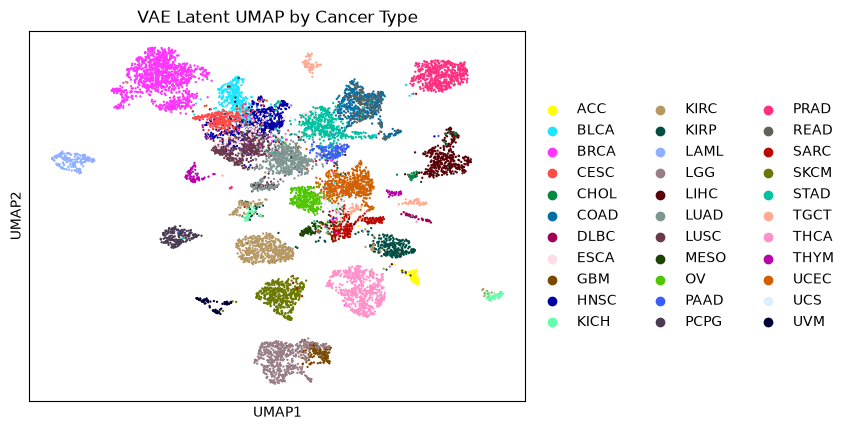

/Users/angadmiglani/venvs/reveal-genomics/lib/python3.14/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


/Users/angadmiglani/venvs/reveal-genomics/lib/python3.14/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


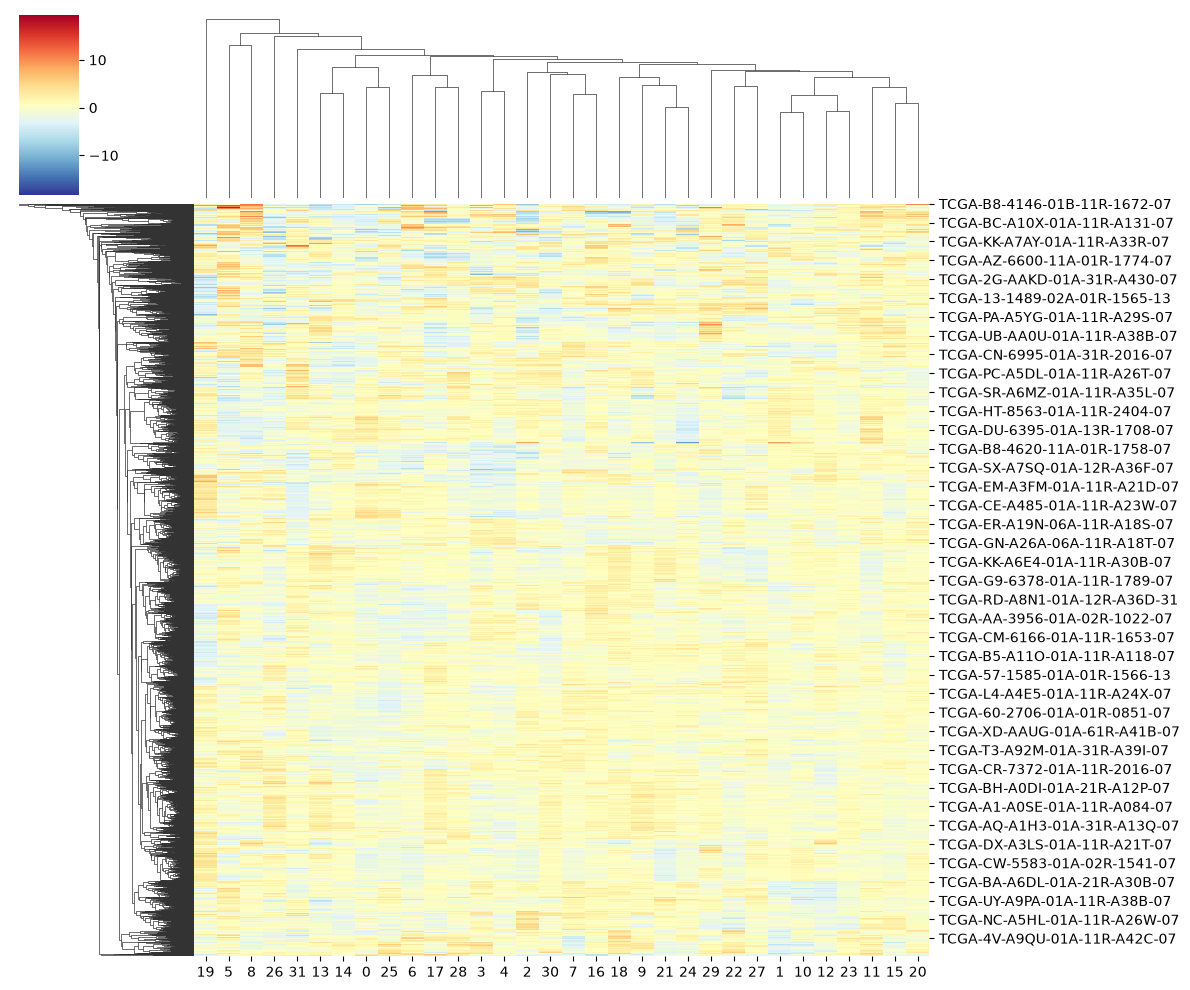

In [7]:
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

# UMAP (Figure 2A/B)
sc.pp.neighbors(adata, use_rep="X_vae_32")
sc.tl.umap(adata)
sc.pl.umap(adata, color=["cancer type"], title="VAE Latent UMAP by Cancer Type")

# Heatmap (Figure 2C)
latent_df = pd.DataFrame(adata.obsm["X_vae_32"], index=adata.obs_names)
sns.clustermap(latent_df, row_cluster=True, col_cluster=True, cmap="RdYlBu_r", figsize=(12,10))
plt.show()


# Description of the Work

I implemented a **Variational Autoencoder (VAE)** to learn a low-dimensional latent representation of the TCGA Pan-Cancer RNA-seq dataset.

---

## Data Preprocessing

* Gene expression data (16,335 features per tumor sample) was preprocessed by:

  * Removing missing values
  * Filtering metadata
  * Log-normalizing counts
  * Merging expression data with sample metadata
* The final dataset was stored in an **AnnData** object (`adata_tcga`) and exported as a `.h5ad` file for downstream analysis.

---

## Model Architecture

* The VAE consists of:

  * **Encoder**: compresses high-dimensional gene expression profiles into a **32-dimensional latent space**.
  * **Latent Layer**: outputs both a mean (`μ`) and log-variance (`logσ²`) for each latent variable. Using the **reparameterization trick**, latent embeddings are sampled.
  * **Decoder**: reconstructs the original expression profiles from the latent space.

---

## Loss Function

Training minimized a combined loss of:

1. **Reconstruction Loss**: Mean squared error between the input and reconstructed output.
2. **Kullback–Leibler Divergence (KL)**: Forces the latent distribution to align with a unit Gaussian prior, improving generalizability and structure of the latent space.

---

## Training

* Optimizer: **Adam**
* Regularization: **Dropout**
* Mini-batch training with a **validation split**
* Model trained for 50 epochs

---

## Results (Replicating Figure 2 from Tybalt VAE Paper)

* **UMAP Projections (Figure 2A/B):**
  Latent embeddings projected into 2D using UMAP showed that samples clustered by cancer type. This indicates that the VAE captured biologically meaningful patterns in the data.

* **Heatmap of Encodings (Figure 2C):**
  A heatmap of the latent encodings revealed structured variation across tumors. Hierarchical clustering highlighted groups of samples with similar expression programs, consistent with distinct cancer-type biology.

---

## Significance

The VAE successfully extracted a **compact latent space** where cancer types formed coherent clusters. This demonstrates the ability of deep generative models to uncover biologically relevant features from large-scale gene expression datasets.

This work mirrors the results of the **Tybalt VAE** paper (PubMed ID: [29218871](https://pubmed.ncbi.nlm.nih.gov/29218871/)), confirming that VAEs can be powerful tools for cancer stratification and for modeling gene expression landscapes.

# Task
Train the autoencoder using the `X` data, and then create a pandas DataFrame containing the generated 32-dimensional latent embeddings (`Z`), using `adata_tcga.obs_names` as the index.

## Train Autoencoder and Generate Embeddings

### Subtask:
Execute the `train_autoencoder` function with the preprocessed data (X) to obtain the 32-dimensional latent embeddings (Z) for all cells.


**Reasoning**:
The user wants to execute the `train_autoencoder` function with the preprocessed data `X`, specifying `latent_dim=32` and `epochs=50`, and store the results in `model` and `Z`. This directly addresses the subtask instructions.



In [4]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.preprocessing import StandardScaler
import anndata as ad

# ----- Autoencoder model -----
class AE(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden=[1024, 256, 64], dropout=0.1):
        super().__init__()
        enc_layers = []
        last = input_dim
        for h in hidden:
            enc_layers += [nn.Linear(last, h), nn.ReLU(), nn.Dropout(dropout)]
            last = h
        enc_layers += [nn.Linear(last, latent_dim)]
        self.encoder = nn.Sequential(*enc_layers)

        dec_layers = []
        last = latent_dim
        for h in reversed(hidden):
            dec_layers += [nn.Linear(last, h), nn.ReLU(), nn.Dropout(dropout)]
            last = h
        dec_layers += [nn.Linear(last, input_dim)]
        self.decoder = nn.Sequential(*dec_layers)

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

def train_autoencoder(X, latent_dim=32, hidden=[1024,256,64],
                      dropout=0.1, batch_size=256, lr=1e-3,
                      weight_decay=1e-5, epochs=50, val_split=0.1, seed=42):

    torch.manual_seed(seed)
    np.random.seed(seed)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    n_cells, n_genes = X.shape

    model = AE(input_dim=n_genes, latent_dim=latent_dim, hidden=hidden, dropout=dropout).to(device)

    X_tensor = torch.from_numpy(X)
    dataset = TensorDataset(X_tensor)
    n_val = int(len(dataset) * val_split)
    n_train = len(dataset) - n_val
    train_ds, val_ds = random_split(dataset, [n_train, n_val], generator=torch.Generator().manual_seed(seed))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    for epoch in range(1, epochs+1):
        # Training
        model.train()
        train_loss = 0.0
        for (xb,) in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            x_hat, _ = model(xb)
            loss = criterion(x_hat, xb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= n_train

        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for (xb,) in val_loader:
                xb = xb.to(device)
                x_hat, _ = model(xb)
                loss = criterion(x_hat, xb)
                val_loss += loss.item() * xb.size(0)
        val_loss /= n_val

        print(f"Epoch {epoch:03d}/{epochs}  train MSE: {train_loss:.6f}  val MSE: {val_loss:.6f}")

    # Extract embeddings
    model.eval()
    with torch.no_grad():
        Z = []
        for i in range(0, X.shape[0], 4096):
            xb = torch.from_numpy(X[i:i+4096]).to(device)
            _, z = model(xb)
            Z.append(z.cpu().numpy())
        Z = np.vstack(Z).astype(np.float32)

    return model, Z

# Prepare data (X) for training
# Uses the cleaned `adata` (NaN genes removed) from the "Train the VAE Model" cell above
X = adata.X
if not isinstance(X, np.ndarray):
    X = X.A if hasattr(X, "A") else X.toarray()
X = X.astype(np.float32)

scaler = StandardScaler()
X = scaler.fit_transform(X).astype(np.float32)

# Train
model, Z = train_autoencoder(X, latent_dim=32, epochs=50)

# 32-dim latent embeddings, one row per sample
ae_embeddings_df = pd.DataFrame(Z, index=adata.obs_names, columns=[f"latent_{i}" for i in range(Z.shape[1])])
ae_embeddings_df.head()

Epoch 001/50  train MSE: 0.767053  val MSE: 0.595846


Epoch 002/50  train MSE: 0.581104  val MSE: 0.510833


Epoch 003/50  train MSE: 0.523010  val MSE: 0.463264


Epoch 004/50  train MSE: 0.489391  val MSE: 0.439712


Epoch 005/50  train MSE: 0.469085  val MSE: 0.428288


Epoch 006/50  train MSE: 0.454342  val MSE: 0.416241


... (41 outputs left out)

Epoch 048/50  train MSE: 0.381307  val MSE: 0.361037


Epoch 049/50  train MSE: 0.379087  val MSE: 0.363065


Epoch 050/50  train MSE: 0.379600  val MSE: 0.365111


,latent_0,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6,latent_7,latent_8,latent_9,...,latent_22,latent_23,latent_24,latent_25,latent_26,latent_27,latent_28,latent_29,latent_30,latent_31
TCGA-OR-A5J1-01A-11R-A29S-07,1.555271,6.016219,19.231314,-22.656637,2.958576,-0.902974,37.767033,-0.559874,27.708389,15.738163,...,18.919420,-30.106493,27.826832,20.180130,11.268992,17.867146,3.991805,-59.241577,-14.659554,-27.457989
TCGA-OR-A5J2-01A-11R-A29S-07,-3.173739,9.093813,22.434700,-10.014094,7.613152,-12.837072,13.322341,1.754130,25.748070,28.674734,...,12.665211,-8.914113,10.557784,-0.694958,11.126964,2.834077,4.956962,-20.859606,-12.986331,-6.330489
TCGA-OR-A5J3-01A-11R-A29S-07,-10.450802,16.288645,26.427782,-21.215527,10.807986,-10.211754,30.330612,11.797050,46.304028,39.564880,...,26.337137,-30.686516,15.637637,2.348994,5.732836,13.570994,14.801316,-37.614376,-15.073682,-17.244074
TCGA-OR-A5J5-01A-11R-A29S-07,4.391111,0.639957,-7.598221,-39.745327,-12.734115,5.309610,56.551880,32.444122,34.836308,42.156860,...,7.768108,-23.975006,53.203583,40.361012,7.927938,27.172331,-6.554914,-55.481945,-22.501274,-31.688976
TCGA-OR-A5J6-01A-31R-A29S-07,-20.740948,26.898146,20.231533,-18.887197,9.425016,-18.699526,15.014426,1.655887,27.049875,15.439266,...,25.812288,-41.368401,29.866463,-4.279715,-0.081484,26.851171,21.764799,-38.399929,-24.927864,-27.936674
